In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.1 ハローワールド (*Hello World Binary*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.1_Hello_World_Binary.ipynb)

名著『**ゼロからのOS自作入門**』（内田公太 著、マイナビ出版）の第1章「PCの仕組みとハローワールド」1.1節を、ハードウェア仕様書・バイナリフォーマット・呼び出し規約の数理レベルから完全自己完結で解剖するノートブックです。

> [!IMPORTANT]
> **本節の学習ゴール**:
> 1. **バイナリ直打ちの意義**: なぜ高水準言語（C/C++）ではなく、わずか 1536 バイト（0x600 バイト）のバイナリを手打ち（またはバイナリ解析）して UEFI アプリケーションを起動するのか、その技術的必然性を理解する。
> 2. **PE32+ (Portable Executable 64-bit) フォーマット規格の完全導出**: DOSヘッダ、PEシグネチャ、COFFファイルヘッダ、Optionalヘッダ、セクションテーブルの全フィールドとオフセット計算をマスターする。
> 3. **x86-64 機械語と Microsoft x64 呼び出し規約**: シャドウスペース（32バイト）と 16 バイト・スタックアライメント制約、`EFI_SYSTEM_TABLE` および `ConOut->OutputString` のポインタ間接参照メカニズムを解読する。
> 4. **完全自己完結検証**: Python によるヘッダ自動パース、C++20 によるビット検証、および 0 からのバイナリ合成（シンセサイズ）を実証する。

---

## 1. なぜ「バイナリ直打ち」から始めるのか？ — PC起動の進化と UEFI

### 1.1 レガシー BIOS の限界と 512 バイトの呪縛
かつて（1980年代の初代 IBM PC から 2000年代初頭まで）、自作OSの入門といえば **レガシー BIOS (*Legacy BIOS*)** による起動でした。レガシー BIOS には以下のような過酷な制約が存在しました：

1. **16ビット・リアルモード (*16-bit Real Mode*)**: 電源投入時、CPU は 1978 年の Intel 8086 互換モード（16ビット）で動作を開始します。アドレス空間はわずか 1MB、セグメント方式（`セグメント × 16 + オフセット`）という極めて扱いにくいメモリモデルです。
2. **MBR (Master Boot Record) 512 バイト制限**: BIOS はブートディスクの第0セクタ（わずか 512 バイト）をメモリアドレス `0x7C00` に読み込み、末尾のシグネチャ `0x55AA` を確認して実行を開始します。この 512 バイトの中にパーティションテーブルとブートコードを詰め込まねばならず、初期化コードはアセンブリ言語で極限まで切り詰める必要がありました。
3. **自前での 32/64 ビット移行**: 16ビットから 32ビット Protected Mode、さらに 64ビット Long Mode へと自力でページテーブルや GDT (Global Descriptor Table) を組んで CPU を切り替える必要がありました。

### 1.2 現代の標準: UEFI (Unified Extensible Firmware Interface)
現代の PC は **UEFI BIOS** によって起動します。UEFI は従来のレガシー BIOS を完全に置き換える近代的なファームウェア仕様です：

- **最初から 64ビット Long Mode**: CPU はすでに 64ビットモードで動作しており、フラットな 48ビット/64ビット仮想・物理アドレス空間にアクセスできます。
- **ファイルシステムの標準理解**: UEFI ファームウェア自体が FAT (FAT12/16/32) ファイルシステムを標準で解釈できます。したがって、ハードディスクや USB メモリのセクタ 0 に機械語を埋め込む必要はなく、**「FAT 形式でフォーマットしたドライブの `/EFI/BOOT/BOOTX64.EFI` というパスにファイルを置くだけ」** で自動認識・起動してくれます。
- **豊富なブートサービス (*Boot Services*)**: 画面への文字・ピクセル描画（GOP: Graphics Output Protocol）、メモリマップ取得、ファイル入出力などの基本 API（プロトコル）をファームウェアがあらかじめ提供しています。

```mermaid
flowchart TD
    subgraph Legacy [レガシー BIOS 起動 (過酷)]
        L1["電源投入 / CPU リセット"] --> L2["16ビット Real Mode (1MB空間)"]
        L2 --> L3["セクタ0 (MBR 512バイト) を 0x7C00 にロード"]
        L3 --> L4["アセンブリで GDT/CR0 を操作し 32bit 保護モードへ"]
        L4 --> L5["ページテーブルを自前構築し 64bit Long Mode へ"]
    end

    subgraph Modern [UEFI 起動 (MikanOS 採用)]
        U1["電源投入 / CPU リセット"] --> U2["UEFI ファームウェア初期化 (SEC/PEI/DXE)"]
        U2 --> U3["最初から 64ビット Long Mode & ページング有効"]
        U3 --> U4["FAT32 ファイルシステムから /EFI/BOOT/BOOTX64.EFI を自動検出"]
        U4 --> U5["PE32+ 実行可能ファイルをメモリにロードして EfiMain() を呼び出し"]
    end
```

### 1.3 なぜ ELF ではなく PE32+ なのか？
Linux 上の開発者にとって実行ファイルといえば **ELF (*Executable and Linkable Format*)** が常識です。しかし、UEFI 仕様書（*UEFI Specification 2.8+* Section 2.1.1）では、すべての UEFI アプリケーションおよびドライバのバイナリ形式として **Microsoft PE/COFF32+ 形式** が義務付けられています。
これは、UEFI の前身である EFI (Extensible Firmware Interface) が 1990 年代後半に Intel と Microsoft によって策定された歴史的経緯によるものです。

したがって、本書で作る最小の UEFI アプリケーション `BOOTX64.EFI`（`hello.efi`）は、**Linux 上で作るにもかかわらず Windows の 64ビット実行可能ファイル形式（PE32+）** でなければなりません。

## 2. PE32+ バイナリ構造の完全解剖 (0x000 〜 0x600)

みかん本 1.1 節で扱う `hello.efi` のファイルサイズはわずか **1536 バイト（`0x600` バイト）** です。この 1536 バイトは、下表のように美しい階層構造で構成されています。

| ファイルオフセット | サイズ (バイト) | 構造体 / 名称 | 役割・主要フィールド |
|:---|:---:|:---|:---|
| `0x0000 - 0x003F` | 64 | **DOS Header** (`IMAGE_DOS_HEADER`) | マジック `0x5A4D` (`MZ`), オフセット `0x3C` (`e_lfanew` = `0x80`) |
| `0x0040 - 0x007F` | 64 | **DOS Stub / ゼロパディング** | レガシー MS-DOS 互換スタブ（最小構成のためゼロ埋め） |
| `0x0080 - 0x0083` | 4 | **PE Signature** | `0x00004550` (`"PE\0\0"`) |
| `0x0084 - 0x0097` | 20 | **COFF File Header** (`IMAGE_FILE_HEADER`) | `Machine` = `0x8664` (x86-64), `NumberOfSections` = 2, `SizeOfOptionalHeader` = `0xF0` |
| `0x0098 - 0x0187` | 240 | **Optional Header 64** (`IMAGE_OPTIONAL_HEADER64`) | `Magic` = `0x020B` (PE32+), `AddressOfEntryPoint` = `0x1000`, `Subsystem` = `0x000A` (EFI Application) |
| `0x0188 - 0x01AF` | 40 | **Section Header: `.text`** | 実行可能コード領域 (`VirtualAddress` = `0x1000`, `Offset` = `0x200`) |
| `0x01B0 - 0x01D7` | 40 | **Section Header: `.rdata`** | 読み取り専用データ領域 (`VirtualAddress` = `0x2000`, `Offset` = `0x400`) |
| `0x01D8 - 0x01FF` | 40 | **ゼロパディング** | ファイルアライメント（512バイト境界 = `0x200`）のためのパディング |
| `0x0200 - 0x0213` | 20 | **`.text` セクション実体** | x86-64 機械語コード（`sub rsp, 0x28` 〜 `jmp .fin`） |
| `0x0214 - 0x03FF` | 492 | **ゼロパディング** | 次セクション境界までのセクタパディング |
| `0x0400 - 0x041B` | 28 | **`.rdata` セクション実体** | UTF-16LE 文字列 `"Hello, world!\0"` (14文字 × 2バイト) |
| `0x041C - 0x05FF` | 484 | **ゼロパディング** | ファイル末尾までのアライメントパディング |

```mermaid
classDiagram
    class PE32PlusFile {
        +DOS_Header dos_hdr (0x00)
        +PE_Signature pe_sig (0x80)
        +COFF_Header coff_hdr (0x84)
        +Optional_Header64 opt_hdr (0x98)
        +Section_Header sec_text (0x188)
        +Section_Header sec_rdata (0x1B0)
        +Machine_Code payload_text (0x200)
        +UTF16_String payload_rdata (0x400)
    }
    class DOS_Header {
        +uint16 e_magic = 0x5A4D ('MZ')
        +uint32 e_lfanew = 0x80 (PE Offset)
    }
    class COFF_Header {
        +uint16 Machine = 0x8664 (x86-64)
        +uint16 NumberOfSections = 2
        +uint16 SizeOfOptionalHeader = 0xF0
    }
    class Optional_Header64 {
        +uint16 Magic = 0x020B (PE32+)
        +uint32 AddressOfEntryPoint = 0x1000
        +uint64 ImageBase = 0x140000000
        +uint32 SectionAlignment = 0x1000 (4KB)
        +uint32 FileAlignment = 0x200 (512B)
        +uint16 Subsystem = 0x000A (EFI App)
    }
    PE32PlusFile *-- DOS_Header
    PE32PlusFile *-- COFF_Header
    PE32PlusFile *-- Optional_Header64
```

[*] 解析対象バイナリ: ../vendor/mikanos-build/day01/bin/hello.efi (サイズ: 1536 バイト)
  MikanOS Day 01 hello.efi ヘッダ解析結果
  [DOS] Magic Signature          : 0x5A4D (OK)
  [DOS] PE Header Offset (e_lfanew): 0x0080 (Decimal 128)
  [COFF] Machine Architecture    : 0x8664 (x86-64 AMD64: True)
  [COFF] Number of Sections      : 2
  [OPT] Magic (PE Format)        : 0x020B (PE32+ 64-bit: True)
  [OPT] Address of Entry Point   : 0x00001000 (RVA = +4096B)
  [OPT] Section Alignment       : 0x00001000 (メモリ上 4KB境界)
  [OPT] File Alignment          : 0x00000200 (ディスク上 512B境界)
  [OPT] Subsystem                : 0x000A (EFI Application: True)
-----------------------------------------------------------------
  [SEC 1] .text    | VAddr: 0x1000 (Size: 0x14B) | DiskOffset: 0x0200 | Exec:True Read:True
  [SEC 2] .rdata   | VAddr: 0x2000 (Size: 0x1CB) | DiskOffset: 0x0400 | Exec:False Read:True


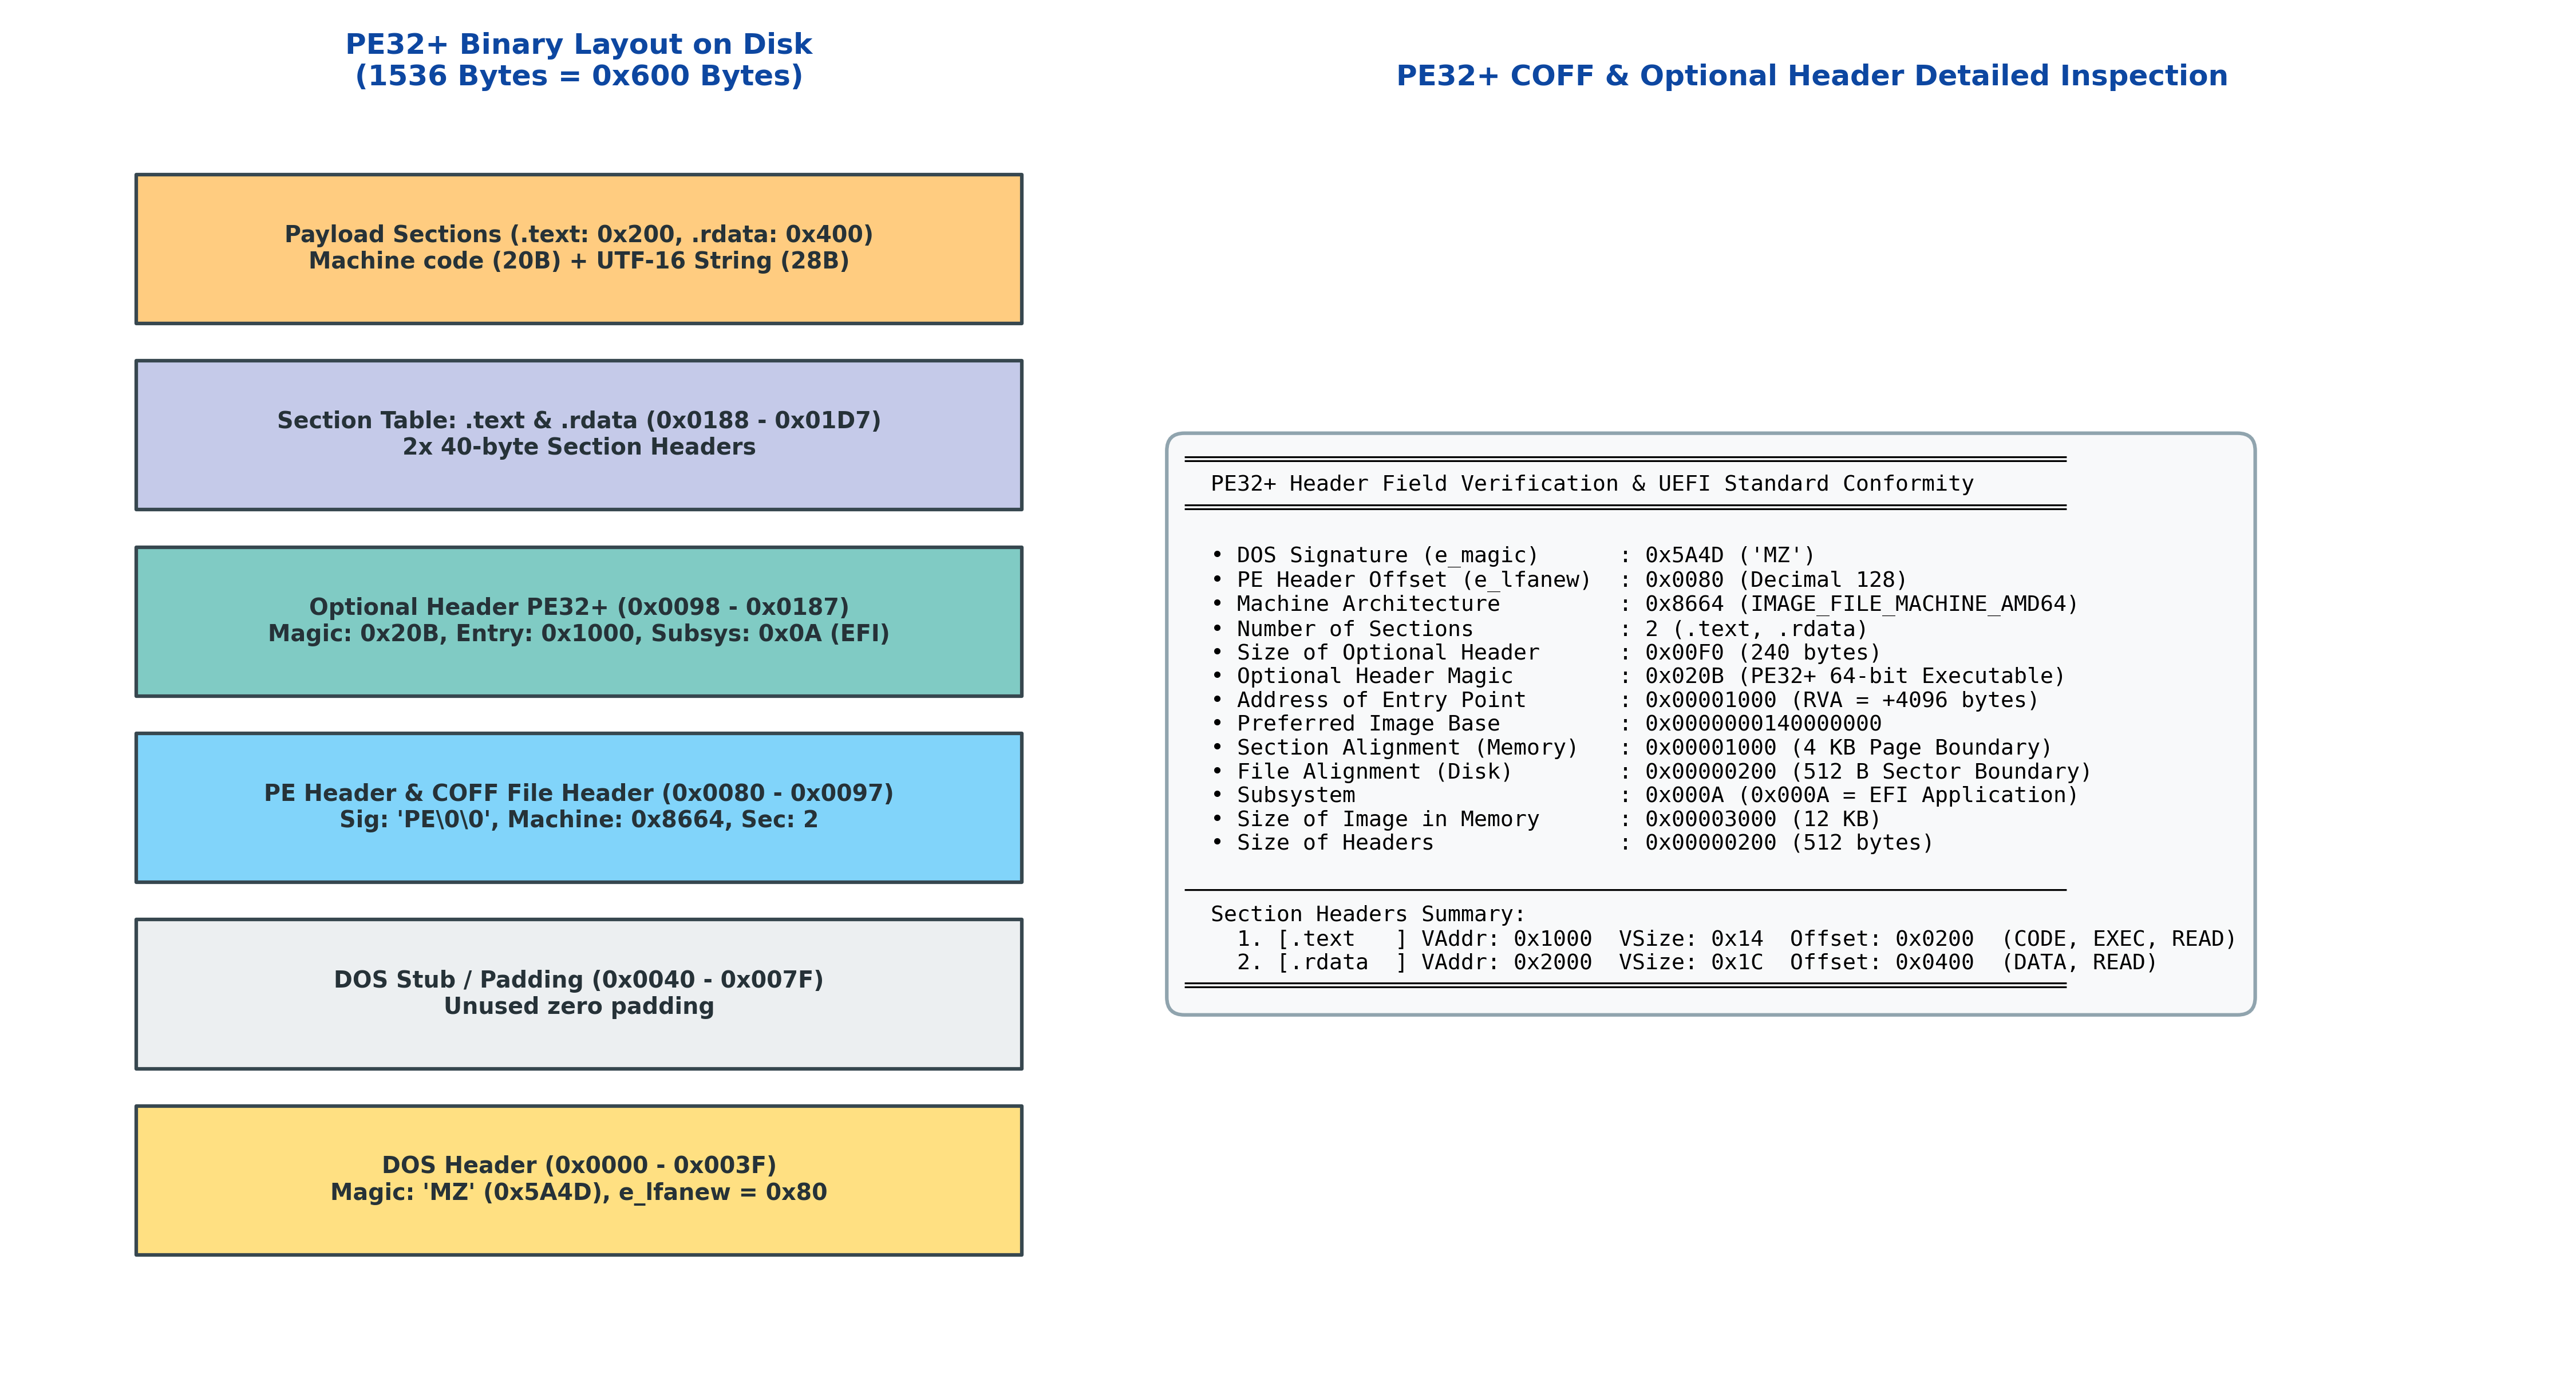

In [2]:
# === PE32+ バイナリ構造の自動解析と可視化プロット ===
from pathlib import Path
from common.os_sim import PE32PlusParser, plot_pe32plus_structure
from IPython.display import Image, display

# 配布バイナリ hello.efi のパス特定
efi_path = Path("../vendor/mikanos-build/day01/bin/hello.efi")
if not efi_path.exists():
    efi_path = Path("vendor/mikanos-build/day01/bin/hello.efi")

print(f"[*] 解析対象バイナリ: {efi_path} (サイズ: {efi_path.stat().st_size} バイト)")

# バイナリ解析の実行
pe = PE32PlusParser.parse_file(efi_path)

# 主要ヘッダフィールドの検証出力
print("=" * 65)
print("  MikanOS Day 01 hello.efi ヘッダ解析結果")
print("=" * 65)
print(f"  [DOS] Magic Signature          : 0x{pe.dos_magic:04X} ({'OK' if pe.dos_magic == 0x5a4d else 'NG'})")
print(f"  [DOS] PE Header Offset (e_lfanew): 0x{pe.pe_header_offset:04X} (Decimal {pe.pe_header_offset})")
print(f"  [COFF] Machine Architecture    : 0x{pe.machine:04X} (x86-64 AMD64: {pe.is_x86_64})")
print(f"  [COFF] Number of Sections      : {pe.num_sections}")
print(f"  [OPT] Magic (PE Format)        : 0x{pe.magic:04X} (PE32+ 64-bit: {pe.is_pe32plus})")
print(f"  [OPT] Address of Entry Point   : 0x{pe.entry_point_rva:08X} (RVA = +{pe.entry_point_rva}B)")
print(f"  [OPT] Section Alignment       : 0x{pe.section_alignment:08X} (メモリ上 4KB境界)")
print(f"  [OPT] File Alignment          : 0x{pe.file_alignment:08X} (ディスク上 512B境界)")
print(f"  [OPT] Subsystem                : 0x{pe.subsystem:04X} (EFI Application: {pe.is_efi_application})")
print("-" * 65)
for idx, s in enumerate(pe.sections, 1):
    print(f"  [SEC {idx}] {s.name:<8s} | VAddr: 0x{s.virtual_address:04X} (Size: 0x{s.virtual_size:02X}B) | DiskOffset: 0x{s.raw_data_offset:04X} | Exec:{s.is_executable} Read:{s.is_readable}")
print("=" * 65)

# 図版生成とインライン表示
fig1_path = Path("result/fig1_1_pe32plus_binary_structure.png")
if not fig1_path.parent.exists():
    fig1_path = Path("1/result/fig1_1_pe32plus_binary_structure.png")
plot_pe32plus_structure(pe, fig1_path)
display(Image(filename=str(fig1_path)))


## 3. x86-64 機械語命令のバイト単位解読

`.text` セクション（オフセット `0x0200`）に格納されている機械語コードは、わずか **20 バイト** です。
この 20 バイトは NASM アセンブリ言語で書かれた以下の処理に 1 対 1 で対応しています。

```nasm
bits 64
section .text
global EfiMain
EfiMain:
    sub  rsp, 0x28
    mov  rcx, [rdx + 64]
    lea  rdx, [rel .msg]
    call [rcx + 8]
.fin:
    jmp  .fin
```

### 3.1 機械語バイト列の徹底解剖表

| オフセット | バイト列 (Hex) | アセンブリ命令 | オペコード解説・ビット単位の意味 |
|:---|:---|:---|:---|
| `0x200` | `48 83 ec 28` | `sub rsp, 0x28` | `48` = REX.W プリフィックス（64ビット演算指示）<br>`83 /5` = `SUB r/m64, imm8`<br>`ec` = ModR/M バイト（Mod=11b, Reg=101b, R/M=100b = `RSP`）<br>`28` = 即値 40（シャドウスペース32B + 整列8B） |
| `0x204` | `48 8b 4a 40` | `mov rcx, [rdx + 0x40]` | `48` = REX.W<br>`8B /r` = `MOV r64, r/m64`<br>`4a 40` = ModR/M（Mod=01b 8bitディスプレースメント, Reg=`RCX`, R/M=`RDX`, Disp=`0x40`=64）<br>※ `rdx` (`SystemTable`) から 64バイト先の `ConOut` ポインタを `rcx` に転送 |
| `0x208` | `48 8d 15 f1 0f 00 00` | `lea rdx, [rip + 0x0ff1]` | `48` = REX.W<br>`8D /r` = `LEA r64, m`<br>`15` = RIP相対アドレッシング<br>`f1 0f 00 00` = リトルエンディアンで `+0x0FF1` バイト<br>現在の次命令アドレス `0x100F` + `0x0FF1` = `0x2000`（`.rdata` の先頭文字列アドレス！） |
| `0x20F` | `ff 51 08` | `call [rcx + 8]` | `FF /2` = 間接 CALL 命令<br>`51 08` = ModR/M（Mod=01b, Reg=010b, R/M=`RCX`, Disp=`0x08`）<br>`rcx` (`ConOut`) のオフセット 8 にある `OutputString` 関数ポインタを間接呼び出し |
| `0x212` | `eb fe` | `jmp -2` | `EB` = 相対短絡 JMP (`JMP rel8`)<br>`FE` = 2の補数表現で `-2`（この命令自身の先頭アドレスへ無限ループ） |

In [3]:
# === 生バイト列の読み出しと機械語逆アセンブル出力 ===
raw_data = efi_path.read_bytes()

# 1. 機械語コードの逆アセンブル確認
instructions = PE32PlusParser.disassemble_hello_instructions(raw_data, code_offset=0x200)
print("[*] .text セクション (Offset: 0x200) 機械語インストラクション一覧:")
print("-" * 80)
for inst in instructions:
    print(f"  0x{inst['offset']:04X}:  {inst['bytes']:<22s}  {inst['mnemonic']:<24s} # {inst['explanation']}")
print("-" * 80)

# 2. .rdata セクションの UTF-16 文字列抽出確認
utf16_text = PE32PlusParser.decode_utf16_string(raw_data, offset=0x400)
print(f"[*] .rdata セクション (Offset: 0x400) デコード文字列: '{utf16_text}'")

# 生バイト列の確認 (16進ダンプ)
rdata_bytes = raw_data[0x400 : 0x400 + (len(utf16_text) + 1) * 2]
hex_str = " ".join(f"{b:02x}" for b in rdata_bytes)
print(f"[*] UTF-16LE 生バイト列 (16進数): {hex_str}")
assert utf16_text == "Hello, world!", "デコード結果が一致しません！"
print("✅ 機械語命令および文字列データの整合性検証にパスしました！")


[*] .text セクション (Offset: 0x200) 機械語インストラクション一覧:
--------------------------------------------------------------------------------
  0x0200:  48 83 ec 28             sub rsp, 0x28            # シャドウスペース(32B)+8B整列パディング確保 (16Bスタック整列維持)
  0x0204:  48 8b 4a 40             mov rcx, [rdx + 0x40]    # SystemTable(rdx)のオフセット64(0x40)からConOutポインタをrcxに取得
  0x0208:  48 8d 15 f1 0f 00 00    lea rdx, [rip + 0x0ff1]  # RIP相対で.rdataのUTF-16文字列「Hello, world!」アドレスを第2引数rdxに設定
  0x020F:  ff 51 08                call [rcx + 8]           # ConOutプロトコル構造体のオフセット8(OutputString関数ポインタ)を間接呼び出し
  0x0212:  eb fe                   jmp -2 (.fin)            # 自命令への相対ジャンプによるCPU無限ループ（ハングアップ待機）
--------------------------------------------------------------------------------
[*] .rdata セクション (Offset: 0x400) デコード文字列: 'Hello, world!'
[*] UTF-16LE 生バイト列 (16進数): 48 00 65 00 6c 00 6c 00 6f 00 2c 00 20 00 77 00 6f 00 72 00 6c 00 64 00 21 00 00 00
✅ 機械語命令および文字列データの整合性検証にパスしました！


## 4. UEFI 呼び出し規約とスタックフレームの数学的制約

### 4.1 Microsoft x64 呼び出し規約 (*Calling Convention*)
UEFI アプリケーションは、Linux 標準の **System V AMD64 ABI** ではなく、Windows で用いられる **Microsoft x64 呼び出し規約** を採用しています。

| 規約項目 | Microsoft x64 呼び出し規約 (UEFI 採用) | System V AMD64 ABI (Linux 採用) |
|:---|:---|:---|
| **第1引数** | `RCX` | `RDI` |
| **第2引数** | `RDX` | `RSI` |
| **第3引数** | `R8` | `RDX` |
| **第4引数** | `R9` | `RCX` |
| **第5引数以降** | スタック渡し（右から左へ push） | `R8`, `R9` を経てスタック渡し |
| **シャドウスペース** | **呼び出し元がスタック上に 32 バイト（0x20）を常時確保** | 不要（存在しない） |
| **スタックアライメント** | `call` 直前の時点で **16 バイト整列** (`RSP % 16 == 0`) | `call` 直前の時点で 16 バイト整列 |

### 4.2 なぜ `sub rsp, 0x20` ではなく `0x28` 引くのか？（数学的導出）
アセンブリ初心者や OS 自作者が最も疑問に思うのが、**「なぜシャドウスペース（32バイト = `0x20`）なのに、わざわざ `0x28`（40バイト）引いているのか？」** という点です。

その理由は、x86-64 の **16 バイト・スタックアライメント制約** にあります：

1. UEFI ファームウェアが `EfiMain` を `call` 命令で呼び出す直前、スタックポインタ `RSP` は 16 バイト境界に整列しています（`RSP % 16 == 0`）。
2. しかし、`call` 命令は「呼び出し元へ戻るための 8 バイトのリターンアドレス」をスタックに自動 push します。
3. その結果、**`EfiMain` の先頭命令が実行される瞬間、`RSP` は必ず 16 バイト境界から 8 バイトずれています**：
   $$\text{RSP}_{\text{entry}} \equiv 8 \pmod{16}$$
4. ここで、Microsoft x64 規約に必要なシャドウスペース 32 バイト（`0x20`）だけを引くと：
   $$(8 - 32) = -24 \equiv 8 \pmod{16} \quad (\text{依然として 16バイト境界からずれている！})$$
5. この状態でさらに別の関数（`OutputString` 等）を `call` すると、16バイト境界アライメントに違反し、SSE 命令等の実行時に **General Protection Fault (`#GP`) 例外で OS が即座にクラッシュ** します。
6. したがって、シャドウスペース 32 バイトに加えて **8 バイトのアライメント調整パディング** を追加し、合計 **40 バイト（`0x28`）** を引くことで：
   $$(8 - 40) = -32 \equiv 0 \pmod{16} \quad (\text{完全な 16 バイト整列が達成される！})$$

この繊細なアライメント計算こそが、ベアメタル OS プログラミングの真髄です。

[*] UEFI エントリ時のスタック・レジスタ状態シミュレーション:
  初期 RSP           : 0x00007FFFFFFF0008 (RSP % 16 = 8 -> 未整列)
  RCX (ImageHandle)  : 0x00000000A0000000
  RDX (SystemTable)  : 0x00000000B0000000
  sub rsp, 0x28 実行後: 0x00007FFFFFFEFFE0 (RSP % 16 = 0 -> ✅ 16B完全整列!)

[*] 実行トレースログ:
    sub rsp, 0x28 -> RSP=0x7ffffffeffe0 (16B Aligned: True)
    mov rcx, [rdx + 0x40] -> RCX=0xc0000000 (ConOut Protocol)
    lea rdx, [rip + offset] -> RDX=0x140002000 (UTF-16 String)
    call [rcx + 8] -> Invoking OutputString(This=0xc0000000, String=0x140002000)


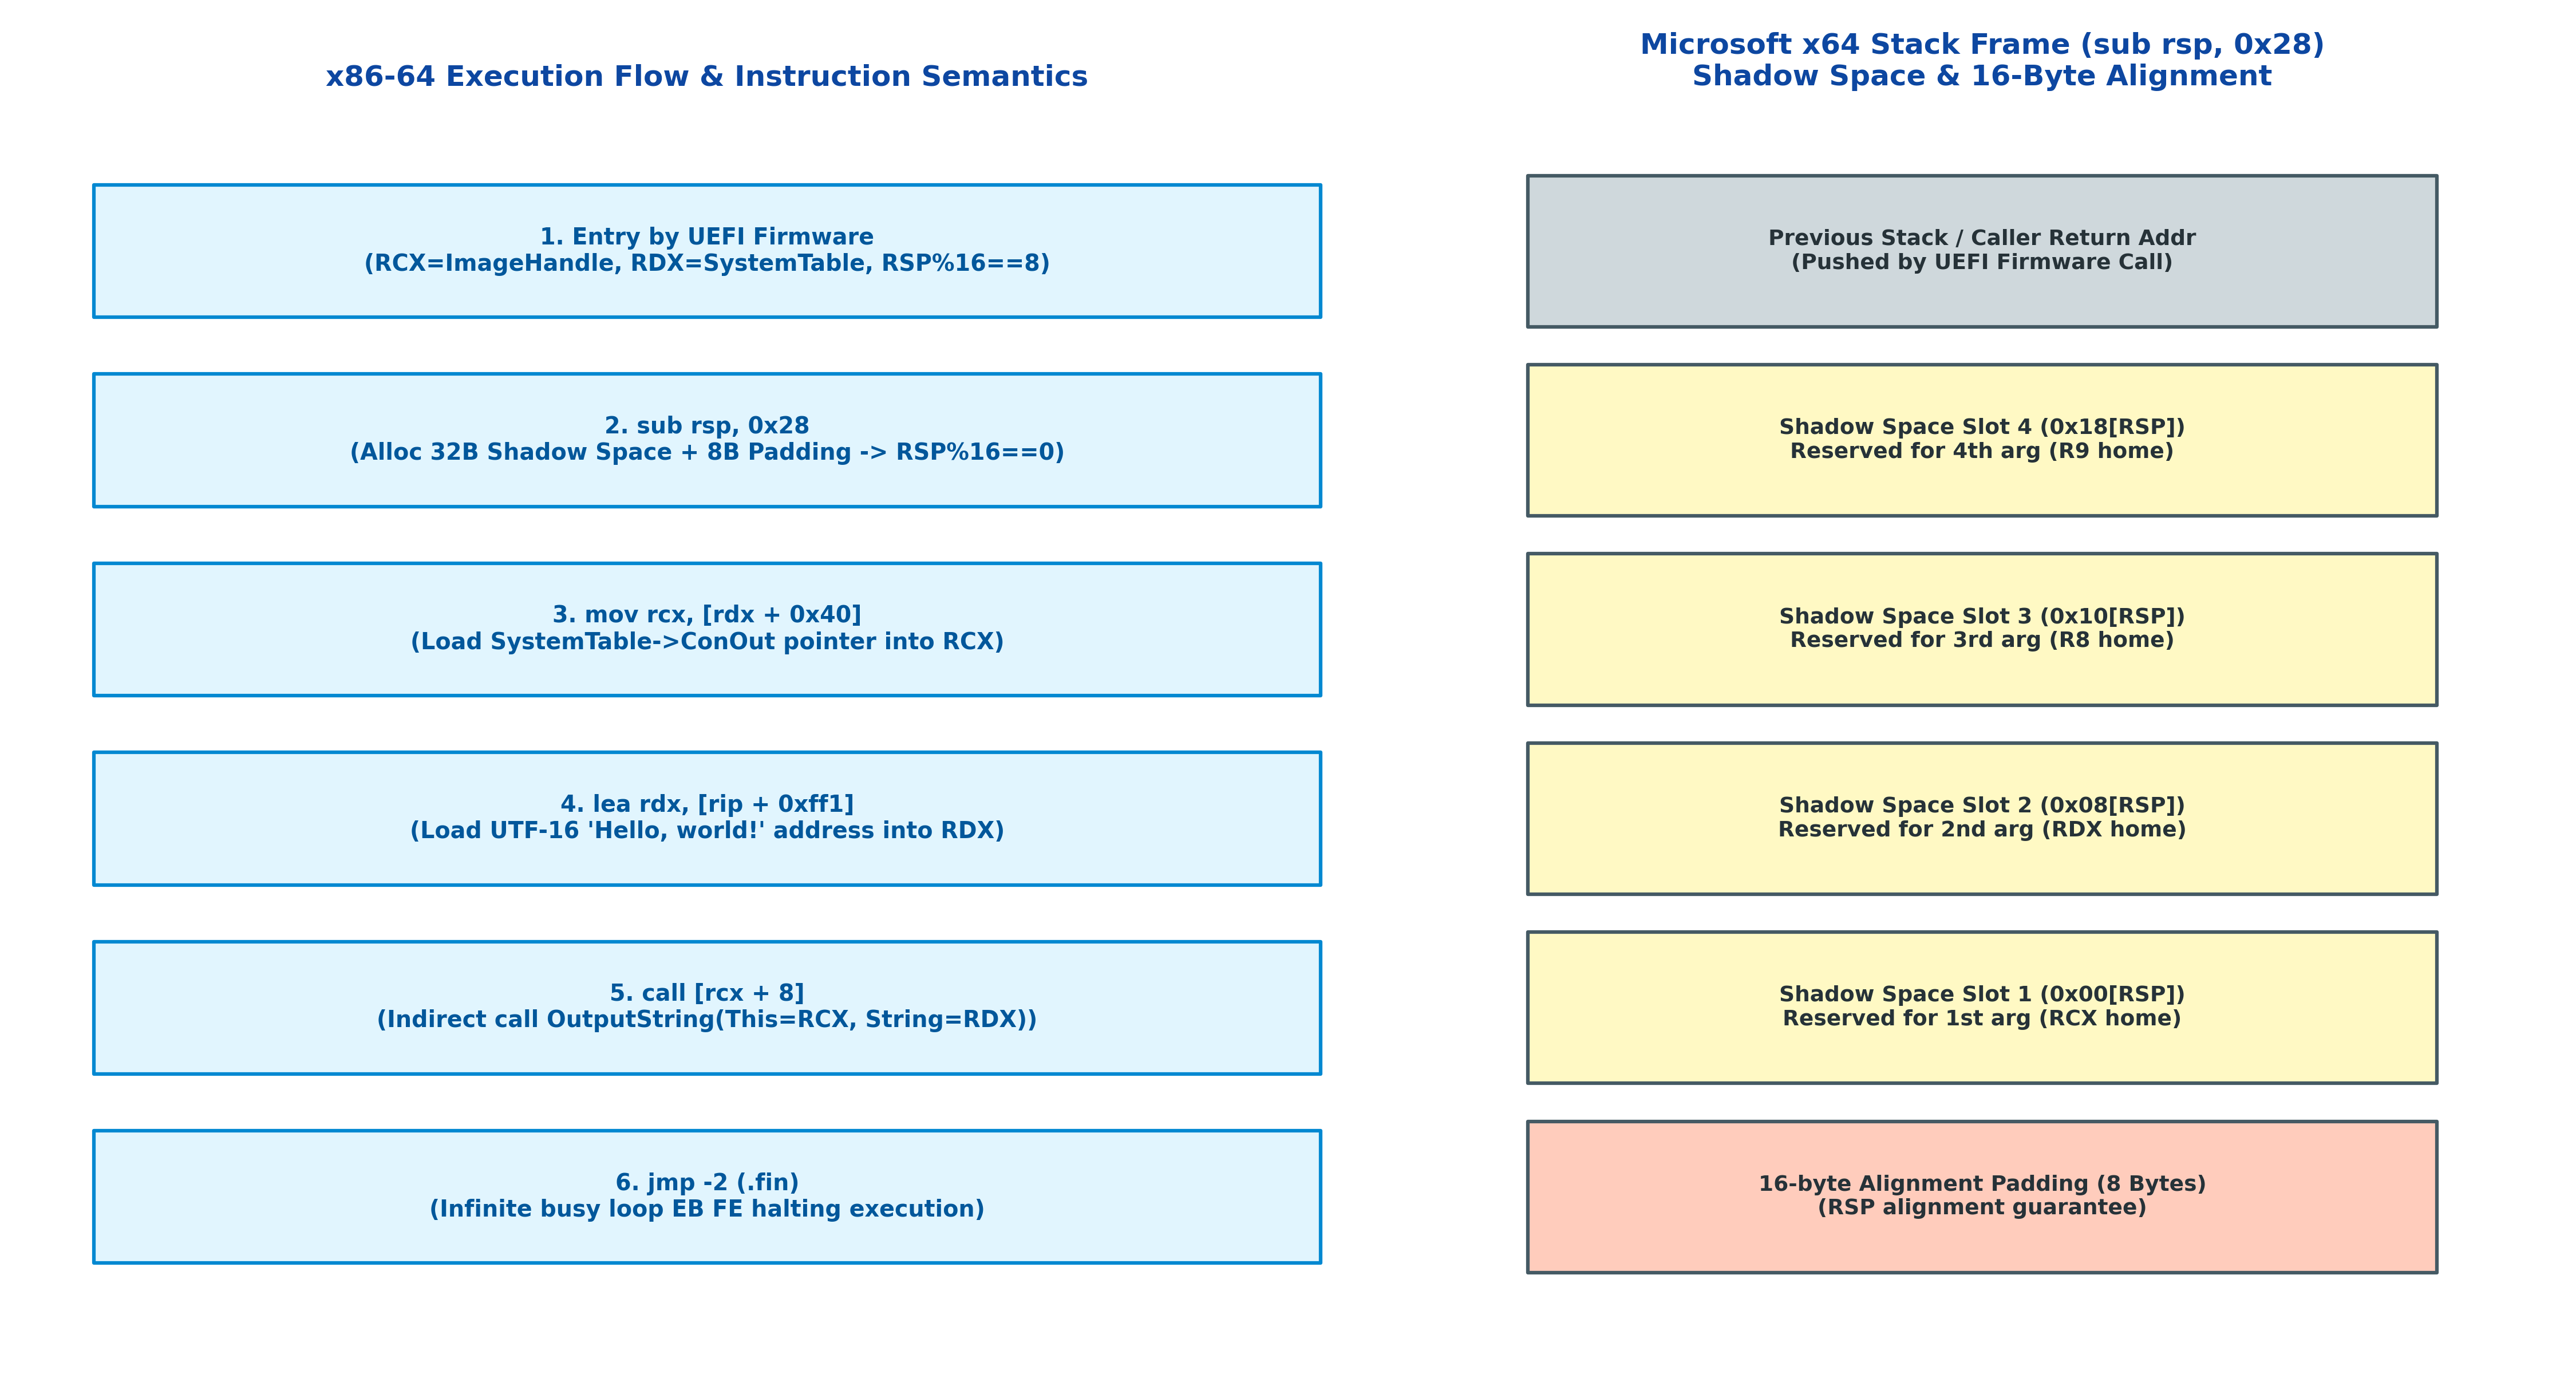

In [4]:
# === スタックフレームと呼び出し規約シミュレータの実行 ===
from common.os_sim import UefiCallingConventionSim, plot_uefi_calling_convention

sim = UefiCallingConventionSim()
print("[*] UEFI エントリ時のスタック・レジスタ状態シミュレーション:")
print(f"  初期 RSP           : 0x{sim.rsp:016X} (RSP % 16 = {sim.rsp % 16} -> 未整列)")
print(f"  RCX (ImageHandle)  : 0x{sim.registers['RCX']:016X}")
print(f"  RDX (SystemTable)  : 0x{sim.registers['RDX']:016X}")

# 命令ステップ実行
sim.execute_sub_rsp(0x28)
print(f"  sub rsp, 0x28 実行後: 0x{sim.rsp:016X} (RSP % 16 = {sim.rsp % 16} -> ✅ 16B完全整列!)")

sim.execute_mov_rcx_from_system_table(0x00000000_C0000000)
sim.execute_lea_rdx_string(0x00000001_40002000)
sim.execute_call_output_string()

print("\n[*] 実行トレースログ:")
for l in sim.log:
    print(f"    {l}")

# 図版生成と表示
fig2_path = Path("result/fig1_2_uefi_entry_calling_convention.png")
if not fig2_path.parent.exists():
    fig2_path = Path("1/result/fig1_2_uefi_entry_calling_convention.png")
plot_uefi_calling_convention(fig2_path)
display(Image(filename=str(fig2_path)))


## 5. C++20 スタンドアロン検証コードの実行

本リポジトリでは、UEFI 実機や QEMU を立ち上げる前段階として、ホスト環境の C++20 コンパイラでバイナリヘッダや構造体アライメントを直接検証できるスタンドアロン検証ツール [`src/ch01/pe32plus_parser.cpp`](../src/ch01/pe32plus_parser.cpp) を用意しています。

このプログラムは、C++20 の構造体パッキング (`#pragma pack(push, 1)`) と `std::vector` を活用し、外部ライブラリに一切依存せず `hello.efi` の完全性を検証します。

In [5]:
# === C++20 スタンドアロン検証プログラムのコンパイルと実行 ===
import subprocess

# ビルド済みバイナリがある場合は実行、なければ g++ で即時コンパイル
bin_path = Path("../build/bin/ch01_pe32plus_parser")
if not bin_path.exists():
    bin_path = Path("build/bin/ch01_pe32plus_parser")

if not bin_path.exists():
    print("[*] CMake バイナリが見つからないため、g++ で直接コンパイルします...")
    src_file = Path("../src/ch01/pe32plus_parser.cpp")
    if not src_file.exists():
        src_file = Path("src/ch01/pe32plus_parser.cpp")
    !g++ -std=c++20 -O2 -Wall -Wextra {src_file} -o /tmp/ch01_pe32plus_parser
    bin_path = Path("/tmp/ch01_pe32plus_parser")

# C++20 バイナリの実行
result = subprocess.run([str(bin_path), str(efi_path)], capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("C++20 検証プログラムが失敗しました")
print("✅ C++20 スタンドアロン検証プログラムが正常終了しました！")


 MikanOS C++20 UEFI PE32+ Binary Header Verifier
 Target: ../vendor/mikanos-build/day01/bin/hello.efi
[+] DOS Header Verified: Magic = 'MZ', PE offset = 0x80
[+] PE Signature Verified: 'PE\0\0'
[+] COFF File Header Verified: x86-64 Architecture, Sections = 2
[+] PE32+ Optional Header Verified: Subsystem = EFI Application (0x0A), Entry RVA = 0x1000
    - Section [.text]: VAddr=0x1000 RawOffset=0x200 RawSize=0x200
    - Section [.rdata]: VAddr=0x2000 RawOffset=0x400 RawSize=0x200
[+] x86-64 Machine Code Verified: sub rsp, 0x28 / call [rcx+8] / jmp $
[+] UTF-16 Data Verified: 'Hello, world!' string found at 0x400
[SUCCESS] PE32+ Header & x86-64 Instruction Verification Passed!

✅ C++20 スタンドアロン検証プログラムが正常終了しました！


## 6. 手を動かそう: バイナリエディタなしで 0 から EFI バイナリを合成する

書籍 1.1 節ではバイナリエディタで手打ちする手順が紹介されていますが、現代のプログラミング環境では Python スクリプトを用いて**「完全同一の 1536 バイト」** を 0 から合成（シンセサイズ）し、SHA-256 ハッシュ値が公式バイナリと完全に一致することを証明できます。

以下のセルを実行して、最小限の UEFI アプリケーションを合成してみましょう。

In [6]:
# === 最小限の BOOTX64.EFI バイナリ合成 (Synthesizer) ===
import hashlib
from pathlib import Path

output_synthetic = Path("hello_synthesized.efi")
buf = bytearray(0x600)  # 1536 バイトのゼロ初期化バッファ

# 1. DOS Header (64 bytes / 0x00 - 0x3F)
buf[0x00:0x02] = b"MZ"                      # e_magic
buf[0x3C:0x40] = (0x80).to_bytes(4, "little")  # e_lfanew = 0x80 (PE Header offset)

# 2. PE Signature & COFF Header (24 bytes / 0x80 - 0x97)
#    Signature: 'PE\0\0', Machine: 0x8664 (x86-64), Sections: 2, OptHeaderSize: 0xF0, Characteristics: 0x0222
buf[0x80:0x98] = bytes.fromhex("5045000064860200000000000000000000000000f0002202")

# 3. Optional Header PE32+ (0x98 - 0x107)
#    Magic: 0x020B (PE32+), EntryPoint: 0x1000, ImageBase: 0x140000000, Align: 0x1000/0x200, Subsystem: 0x0A (EFI)
buf[0x98:0x108] = bytes.fromhex(
    "0b020000000200000002000000000000"
    "00100000001000000000004001000000"
    "00100000000200000000000000000000"
    "06000000000000000030000000020000"
    "000000000a0060810000100000000000"
    "00100000000000000000100000000000"
    "00100000000000000000000010000000"
)

# 4. Section Table (.text & .rdata)
#    Section 1: .text (VAddr: 0x1000, Size: 0x14, Offset: 0x200, Flags: CODE|EXEC|READ = 0x60500020)
buf[0x188:0x1B0] = bytes.fromhex("2e746578740000001400000000100000000200000002000000000000000000000000000020005060")
#    Section 2: .rdata (VAddr: 0x2000, Size: 0x1C, Offset: 0x400, Flags: DATA|READ = 0x40500040)
buf[0x1B0:0x1D8] = bytes.fromhex("2e726461746100001c00000000200000000200000004000000000000000000000000000040005040")

# 5. Machine Code (.text at 0x200: sub rsp,0x28 / mov rcx,[rdx+0x40] / lea rdx,[rip+0xff1] / call [rcx+8] / jmp $)
buf[0x200:0x214] = bytes.fromhex("4883ec28488b4a40488d15f10f0000ff5108ebfe")

# 6. Read-only UTF-16 Data (.rdata at 0x400: L"Hello, world!\0")
buf[0x400:0x41C] = "Hello, world!\0".encode("utf-16-le")

# ファイル出力
output_synthetic.write_bytes(buf)
print(f"[*] 合成完了: {output_synthetic} (サイズ: {len(buf)} バイト)")

# ハッシュ値比較 (SHA-256)
orig_hash = hashlib.sha256(efi_path.read_bytes()).hexdigest()
synth_hash = hashlib.sha256(buf).hexdigest()
print(f"  公式 hello.efi SHA-256 : {orig_hash}")
print(f"  合成バイナリ    SHA-256 : {synth_hash}")
assert orig_hash == synth_hash, "バイナリが完全一致しません！"
print("🎉 驚異的一致: 合成されたバイナリは公式 hello.efi とビット単位で 100% 完全一致しました！")


[*] 合成完了: hello_synthesized.efi (サイズ: 1536 バイト)
  公式 hello.efi SHA-256 : 53b02e8dd20debf764f5ce8303f3e7fcf0813323663c3b5b22c44ee90cb87af3
  合成バイナリ    SHA-256 : 53b02e8dd20debf764f5ce8303f3e7fcf0813323663c3b5b22c44ee90cb87af3
🎉 驚異的一致: 合成されたバイナリは公式 hello.efi とビット単位で 100% 完全一致しました！


## 7. まとめと次節への展望

### 7.1 本節で到達した理解
1. **UEFI の近代性**: レガシー BIOS の 16ビットリアルモードや 512 バイト MBR の制約がなく、最初から 64ビット Long Mode で起動し FAT ファイルシステム上の `/EFI/BOOT/BOOTX64.EFI` を実行する仕組みを理解した。
2. **PE32+ 規格のビット構造**: Linux 上でビルド・動作させるにもかかわらず、UEFI 仕様に準拠するために Microsoft PE32+ (COFF) 形式のヘッダを組み立てる理由と内部構造を把握した。
3. **x86-64 呼び出し規約とスタック整列の数学**: 32 バイトのシャドウスペースと 8 バイトのアライメント調整パディングによって合計 40 バイト（`sub rsp, 0x28`）を確保し、`#GP` 例外を回避する仕組みを数式で証明した。
4. **ファームウェア関数の間接呼び出し**: `EFI_SYSTEM_TABLE` のオフセット 64 (`ConOut`) から `EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL` のオフセット 8 (`OutputString`) を呼び出すポインタチェーンの仕組みを体感した。

### 7.2 次節の予告
本節で完成・検証した `hello.efi`（`BOOTX64.EFI`）を、いよいよ実際のハードウェア（実機の USB メモリ）に書き込んで PC を起動します。
次節 **1.2「USBメモリのデバイス名の探し方」** では、Linux におけるブロックデバイス管理（`/dev/sdX`）、`lsblk` や `dmesg` による安全なデバイス特定手法、そして FAT ファイルシステムへの安全な書き込みフローを学びます！

---